# 1 · What is under the borehole? Two real pumping tests from the Netherlands

**KAI Water & Energy case studies** · [Interactive version on the KAI platform](https://hydro-saas.charkaks0.workers.dev/demo/reference/boreholes) · [Start free](https://hydro-saas.charkaks0.workers.dev/portal?plan=hydrosaas:free) · [kai-water.charkaks0.workers.dev](https://kai-water.charkaks0.workers.dev/)

A pumping test is the cheapest honest measurement of an aquifer: pump a borehole at a steady rate and
watch the water level fall in observation wells nearby. How fast and how far it falls tells you the
aquifer's **transmissivity** *T* (how easily water moves), its **storativity** *S* (how much water it
releases per metre of drawdown) and, when a clay layer leaks water into it, the **resistance** *c* of that layer.

In this notebook you will:

1. load two classic field tests from the Netherlands, published by Kruseman & De Ridder (1990);
2. fit *T*, *S* and *c* with [TTim](https://github.com/mbakker7/ttim), an open-source analytic-element model;
3. check the fit honestly, by leaving each observation well out and predicting it;
4. compare your answer with other published analyses and with the KAI engine;
5. turn the numbers into what an operator wants to know: *how far will my borehole draw down?*

Runtime: about a minute.

## The data

| Test | Aquifer | Pumping | Observation wells |
|---|---|---|---|
| **Oude Korendijk** (polder south of Rotterdam) | confined sand and gravel, 7 m thick, below 18 m of clay | 788 m³/day for about 14 hours | 30 m and 90 m |
| **Dalem** | leaky aquifer, 37 m thick, below an 8 m confining layer | 761 m³/day for 8 hours (readings during pumping only) | 30, 60, 90 and 120 m |

Source: Kruseman, G.P. and De Ridder, N.A. (1990). *Analysis and Evaluation of Pumping Test Data*, 2nd ed.,
ILRI Publication 47, Wageningen. The readings are used as digitised in the TTim documentation
(MIT licence, commit `e757590`), vendored unchanged in `data/pumping-tests/`. Times are minutes (Oude
Korendijk) or days (Dalem); head changes are in metres, negative for drawdown.

In [1]:
import contextlib
import io
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ttim

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data/pumping-tests")
print("TTim", ttim.__version__)

TTim 0.8.0


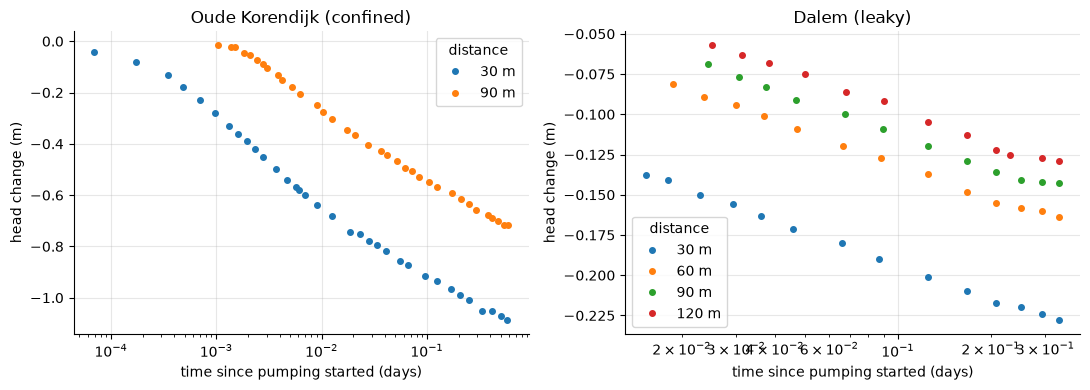

In [2]:
def load(name, minutes):
    a = np.loadtxt(DATA / name, skiprows=1)
    t = a[:, 0] / 1440.0 if minutes else a[:, 0]          # always days
    return t, a[:, 1]

ok_obs = {30: load("piezometer_h30.txt", True), 90: load("piezometer_h90.txt", True)}
dalem_obs = {r: load(f"dalem_p{r}.txt", False) for r in (30, 60, 90, 120)}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (title, obs) in zip(axes, [("Oude Korendijk (confined)", ok_obs), ("Dalem (leaky)", dalem_obs)]):
    for r, (t, h) in obs.items():
        ax.semilogx(t, h, "o", ms=4, label=f"{r} m")
    ax.set(title=title, xlabel="time since pumping started (days)", ylabel="head change (m)")
    ax.legend(title="distance")
plt.tight_layout()

Two different settings. At Oude Korendijk the level keeps falling along a steady line on the log-time axis:
nothing feeds the aquifer and the cone of depression keeps growing (a **confined** aquifer, Theis behaviour).
At Dalem the drawdowns are much smaller for a similar pumping rate in a thicker aquifer under a confining
layer that can leak (a **leaky** aquifer, Hantush behaviour). Within the 8-hour test the Dalem curves do not yet
level off, so the leakage is inferred from the fit, and it is the least certain number of the two tests.

## Fit Oude Korendijk

TTim's `ModelMaq` describes the layers by their elevations. The aquifer runs from 18 m to 25 m below the
surface; the well radius is 0.2 m. We fit hydraulic conductivity *k* and specific storage *Ss*; then
*T = k × thickness* and *S = Ss × thickness*.

In [3]:
def model(kind, k, ss, c=None, q=788.0, z=None, rw=0.2, t_stop=None, tmax=10.0):
    if kind == "leaky":
        ml = ttim.ModelMaq(kaq=k, z=z, c=c, Saq=ss, topboundary="semi", tmin=1e-5, tmax=tmax)
    else:
        ml = ttim.ModelMaq(kaq=k, z=z, Saq=ss, tmin=1e-5, tmax=tmax)
    schedule = [(0, q)] + ([(t_stop, 0)] if t_stop else [])
    ttim.Well(ml, xw=0, yw=0, rw=rw, tsandQ=schedule, layers=0)
    ml.solve(silent=True)
    return ml


def fit(kind, obs, z, q, rw, t_stop=None, use=None):
    use = sorted(obs) if use is None else use
    ml = model(kind, 10.0, 1e-4, 500.0 if kind == "leaky" else None, q=q, z=z, rw=rw, t_stop=t_stop, tmax=12)
    ca = ttim.Calibrate(ml)
    ca.set_parameter(name="kaq0", initial=10)
    ca.set_parameter(name="Saq0", initial=1e-4)
    if kind == "leaky":
        ca.set_parameter(name="c0", initial=500, pmin=0)
    for r in use:
        t, h = obs[r]
        ca.series(name=f"r{r}", x=r, y=0, t=t, h=h, layer=0)
    with contextlib.redirect_stdout(io.StringIO()):   # TTim prints progress dots while fitting
        ca.fit(report=False)
    p = ca.parameters["optimal"].to_numpy(float)
    out = {"k": p[0], "ss": p[1], "rmse": ca.rmse()}
    if kind == "leaky":
        out["c"] = p[2]
    return out


OK = dict(kind="confined", z=[-18.0, -25.0], q=788.0, rw=0.2, t_stop=None)
ok_fit = fit(obs=ok_obs, **OK)
H_OK = 7.0
print(f"Oude Korendijk: T = {ok_fit['k'] * H_OK:.0f} m²/day, S = {ok_fit['ss'] * H_OK:.2e}, RMSE = {ok_fit['rmse'] * 100:.1f} cm")

Oude Korendijk: T = 463 m²/day, S = 1.78e-04, RMSE = 5.0 cm


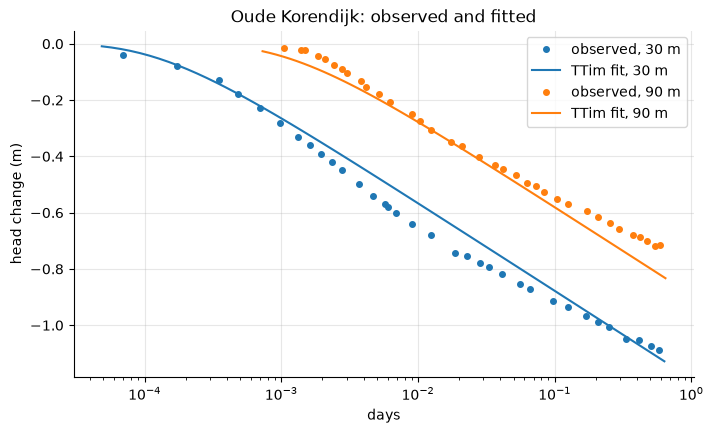

In [4]:
def head(kind, p, r, t, **kw):
    ml = model(kind, p["k"], p["ss"], p.get("c"), tmax=float(np.max(t)) * 1.5, **kw)
    return ml.head(r, 0, t)[0]

fig, ax = plt.subplots()
for i, (r, (t, h)) in enumerate(ok_obs.items()):
    tt = np.geomspace(t.min() * 0.7, t.max() * 1.1, 60)
    ax.semilogx(t, h, "o", ms=4, color=f"C{i}", label=f"observed, {r} m")
    ax.semilogx(tt, head("confined", ok_fit, r, tt, z=OK["z"], q=OK["q"], rw=OK["rw"]), "-", color=f"C{i}", label=f"TTim fit, {r} m")
ax.set(title="Oude Korendijk: observed and fitted", xlabel="days", ylabel="head change (m)")
ax.legend();

## Fit Dalem (leaky)

The aquifer at Dalem lies between 8 m and 45 m below the surface, under a confining layer with resistance
*c* (days). The readings cover the 8 hours of pumping (0.333 days); the model stops the pump just after the last
reading, so it makes no difference to the fit.

Dalem: T = 1677 m²/day, S = 1.76e-03, c = 331 days, leakage factor = 745 m, RMSE = 0.59 cm


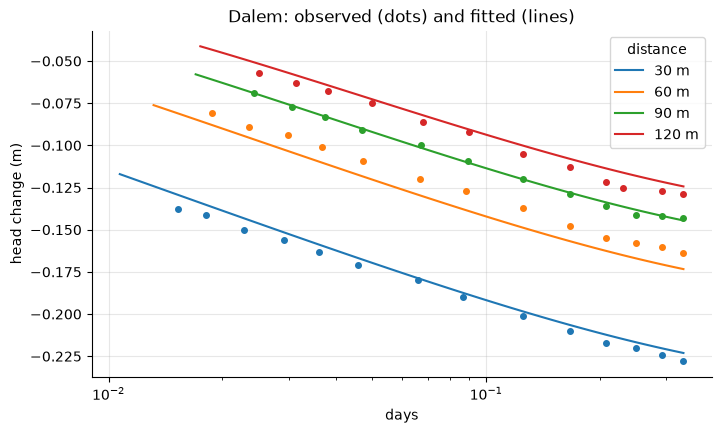

In [5]:
DALEM = dict(kind="leaky", z=[0.0, -8.0, -45.0], q=761.0, rw=0.1, t_stop=0.34)
H_D = 37.0
d_fit = fit(obs=dalem_obs, **DALEM)
leak_factor = np.sqrt(d_fit["k"] * H_D * d_fit["c"])
print(f"Dalem: T = {d_fit['k'] * H_D:.0f} m²/day, S = {d_fit['ss'] * H_D:.2e}, c = {d_fit['c']:.0f} days, "
      f"leakage factor = {leak_factor:.0f} m, RMSE = {d_fit['rmse'] * 100:.2f} cm")

fig, ax = plt.subplots()
for i, (r, (t, h)) in enumerate(dalem_obs.items()):
    tt = np.geomspace(t.min() * 0.7, t.max(), 60)
    ax.semilogx(t, h, "o", ms=4, color=f"C{i}")
    ax.semilogx(tt, head("leaky", d_fit, r, tt, z=DALEM["z"], q=DALEM["q"], rw=DALEM["rw"], t_stop=DALEM["t_stop"]), "-", color=f"C{i}", label=f"{r} m")
ax.set(title="Dalem: observed (dots) and fitted (lines)", xlabel="days", ylabel="head change (m)")
ax.legend(title="distance");

## How good is the fit, honestly?

A fit always matches the data it was fitted to. The honest test is to **leave one observation well out**, fit
the others, and predict the one left out. If the parameters barely move and the prediction is close, the
answer is robust. If one well carries the whole answer, you learn that too.

In [6]:
rows = []
for name, cfg, obs, H in [("Oude Korendijk", OK, ok_obs, H_OK), ("Dalem", DALEM, dalem_obs, H_D)]:
    for r in sorted(obs):
        rest = [x for x in sorted(obs) if x != r]
        p = fit(obs=obs, use=rest, **cfg)
        t, h = obs[r]
        sim = head(cfg["kind"], p, r, t, z=cfg["z"], q=cfg["q"], rw=cfg["rw"], t_stop=cfg["t_stop"])
        c = p.get("c")
        rows.append({"test": name, "left out (m)": r, "error when predicted (cm, RMSE)": np.sqrt(np.mean((sim - h) ** 2)) * 100,
                     "T (m²/day)": p["k"] * H, "S": p["ss"] * H,
                     "c (days)": "" if c is None else ("> 10⁶ (not identifiable)" if c > 1e6 else f"{c:.0f}")})
loo = pd.DataFrame(rows)
loo.style.format({"error when predicted (cm, RMSE)": "{:.1f}", "T (m²/day)": "{:.0f}", "S": "{:.2e}"}).hide(axis="index")

test,left out (m),"error when predicted (cm, RMSE)",T (m²/day),S,c (days)
Oude Korendijk,30,9.9,501,2.04e-04,
Oude Korendijk,90,8.7,480,1.12e-04,
Dalem,30,2.0,2130,1.21e-03,> 10⁶ (not identifiable)
Dalem,60,1.3,1667,1.63e-03,351
Dalem,90,0.1,1674,1.77e-03,322
Dalem,120,1.0,1546,2.13e-03,183


At Dalem, leaving out the **30 m** well makes *c* unidentifiable: without the nearest well the fit cannot see the
leakage at all. The other three fits give *c* between about 180 and 350 days, a wider spread than the formal
standard error of the full fit (± 76 days, one standard deviation, reported by the KAI engine). One more reason
to put an observation well close to the pumped borehole, and to pump longer.

## Compare with other analysts and with the KAI engine

The TTim documentation lists what AQTESOLV and MLU (two commercial packages) and the original authors found
for the same tests. The KAI engine's own result is in `results/kai_engine_results.json`, the same file that
powers the [interactive page on the platform](https://hydro-saas.charkaks0.workers.dev/demo/reference/boreholes).

In [7]:
kai = json.loads(Path("results/kai_engine_results.json").read_text())
table = []
for key, name, mine, H in [("oude_korendijk", "Oude Korendijk", ok_fit, H_OK), ("dalem", "Dalem", d_fit, H_D)]:
    table.append({"test": name, "method": "This notebook (TTim)", "T": mine["k"] * H, "S": mine["ss"] * H, "c": mine.get("c", np.nan)})
    f = kai["tests"][key]["fit"]
    assert abs(mine["k"] * H / f["T"] - 1) < 0.01, "T differs from the published KAI result by more than 1 %"
    table.append({"test": name, "method": "KAI engine", "T": f["T"], "S": f["S"], "c": f.get("c", np.nan)})
    for p in kai["tests"][key]["published"]:
        table.append({"test": name, "method": p["method"], "T": p["T"], "S": p["S"], "c": p.get("c", np.nan)})
pd.DataFrame(table).style.format({"T": "{:.0f}", "S": "{:.2e}", "c": "{:.0f}"}, na_rep="").hide(axis="index")

test,method,T,S,c
Oude Korendijk,This notebook (TTim),463,1.78e-04,
Oude Korendijk,KAI engine,463,1.78e-04,
Oude Korendijk,"Kruseman & De Ridder (Theis, by hand)",390,1.70e-04,
Oude Korendijk,AQTESOLV,463,1.78e-04,
Oude Korendijk,MLU,468,1.68e-04,
Dalem,This notebook (TTim),1677,1.76e-03,331
Dalem,KAI engine,1677,1.76e-03,331
Dalem,AQTESOLV,1824,1.69e-03,745
Dalem,MLU (with aquitard storage),1672,1.46e-03,769


*T* and *S* agree closely with the commercial packages. The leakage resistance *c* at Dalem is smaller in the
TTim fit than in AQTESOLV and MLU; MLU also models storage in the aquitard, which shifts *c*. With 8 hours of
pumping, *c* is the least certain number (see the leave-one-out table), and the reason long tests matter.

## What it means for a borehole owner

The fitted aquifer answers the operator's question: if I pump this borehole continuously at the test rate,
how far will the level fall, in the borehole and 100 m away?

In [8]:
rows = []
for name, cfg, p in [("Oude Korendijk", OK, ok_fit), ("Dalem", DALEM, d_fit)]:
    for label, days in [("1 day", 1.0), ("30 days", 30.0), ("1 year", 365.0)]:
        kw = dict(z=cfg["z"], q=cfg["q"], rw=cfg["rw"], t_stop=None)
        rows.append({"test": name, "pumping for": label,
                     "drawdown in the borehole (m)": -head(cfg["kind"], p, cfg["rw"], np.array([days]), **kw)[0],
                     "drawdown 100 m away (m)": -head(cfg["kind"], p, 100.0, np.array([days]), **kw)[0]})
pd.DataFrame(rows).style.format(precision=2).hide(axis="index")

test,pumping for,drawdown in the borehole (m),drawdown 100 m away (m)
Oude Korendijk,1 day,2.55,0.86
Oude Korendijk,30 days,3.01,1.32
Oude Korendijk,1 year,3.35,1.66
Dalem,1 day,0.65,0.15
Dalem,30 days,0.65,0.15
Dalem,1 year,0.65,0.15


Similar pumping rates, very different futures: at Oude Korendijk the drawdown keeps growing (nothing feeds
the aquifer), at Dalem it levels off within a day because the layer above supplies the water. That difference
decides how many boreholes a wellfield can carry.

The next notebook rebuilds the Dalem aquifer in **MODFLOW 6**, checks it against this real test, and asks a
planning question: what happens with two boreholes 250 m apart?

---

**On the KAI platform**

* [Borehole case, interactive](https://hydro-saas.charkaks0.workers.dev/demo/reference/boreholes): the same results with charts you can explore.
* [HydroSaaS](https://kai-water.charkaks0.workers.dev/hydrosaas.html): borehole drawdown, demand forecasts and water balance for industrial parks.
* [GroundWater Analyst](https://kai-water.charkaks0.workers.dev/groundwater-analyst.html): 3D groundwater models from borehole records.
* [Start free](https://hydro-saas.charkaks0.workers.dev/portal?plan=hydrosaas:free) · [Talk to us about your own pumping test](https://kai-water.charkaks0.workers.dev/contact.html)

*Code: MIT. Text and figures: CC BY 4.0, KAI Water & Energy. Data: Kruseman & De Ridder (1990) via the TTim documentation (MIT).*